> 🔓 **SOLUTIONS EDITION**: this is the instructor copy with worked solutions and executed outputs. Please attempt every problem in the student notebook first; struggling is where learning happens.

# 📘 Lesson 4: Decision Tree Regression
*Twenty questions that carve the world into boxes, and average inside each box*

| ⏱️ Time | 🎚️ Level | 🧰 Prerequisites |
|---|---|---|
| ~120 min | 🟡 Intermediate | Lessons 00–03 |

---
## 🎬 The Hook
Ask an experienced Nairobi estate agent for a price and she doesn't use a formula. She asks questions: *"Which area? … Karen? Okay. How big? … over 2 000 sqft? Does it have a pool?"*, and then names a number: the average of the similar houses she remembers.

That's a **decision tree**. It learns *which questions to ask, in which order, and where to cut*, directly from data. No equations, no assumption of straight lines, and you can read the result like a flowchart.

---
## 🎯 Learning Objectives
By the end of this notebook you will be able to:

1. Explain how a regression tree partitions the feature space and predicts with leaf averages.
2. Derive the split criterion (variance / SSE reduction) and compute it by hand.
3. Implement a regression tree **from scratch** and prove it matches scikit-learn.
4. Tune `max_depth`, `min_samples_leaf` and `ccp_alpha` and diagnose overfitting.
5. Read a tree as a set of human-readable rules, and walk `tree_` arrays manually.
6. Describe the strengths (non-linearity, interactions, no scaling) and weaknesses (instability, no extrapolation, staircase) of trees.

## 🗺️ Roadmap

- The idea: boxes and averages
- The math of a split
- A hand-worked split
- From scratch (and verified against sklearn)
- Overfitting & the complexity dials
- Trees on house prices
- Reading the tree
- Weaknesses: instability & extrapolation
- Cheat-sheet, worked examples, problems, quiz

> 💡 **How to use this notebook:** run cells top to bottom. Read the text *before* you run the code. When you reach a 🧩 **Problem**, try it yourself first, open the hints one at a time, and only then peek at the solutions notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # so we can import course_utils.py
from course_utils import *                      # np, pd, plt, check(), data_path(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
RANDOM_STATE = 42
print("Setup complete ✅")
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve, KFold

Setup complete ✅


---
## 🧠 1. The idea: boxes and averages

A regression tree repeatedly asks yes/no questions of the form **"is feature *j* ≤ threshold *t*?"**. Each question splits the data in two. After a few splits the feature space is carved into rectangles (**leaves**). The prediction for a new point is the **mean target value** of the training points in its rectangle.

With one feature the result is a **staircase** function. Let's watch one grow on noisy curved data:

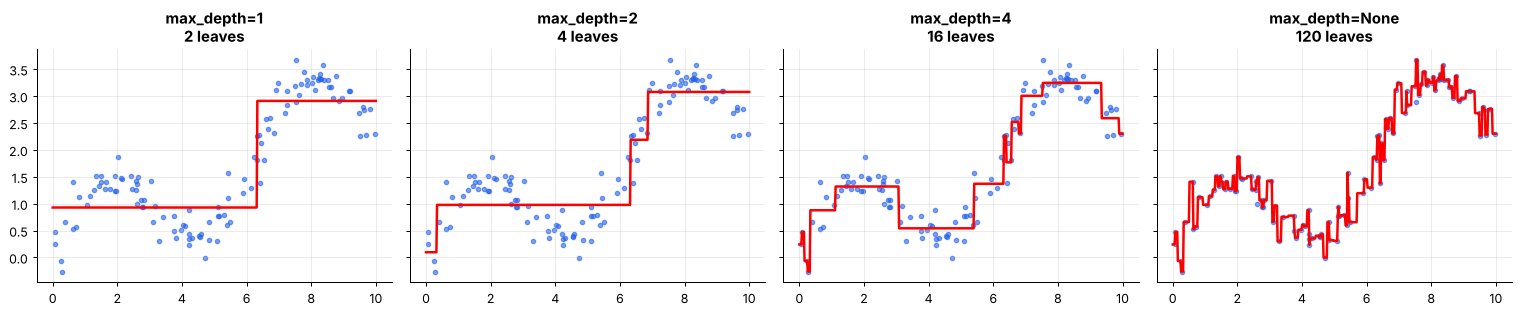

In [2]:
rng = np.random.default_rng(1)
x1 = np.sort(rng.uniform(0, 10, 120)); y1 = np.sin(x1) + 0.3 * x1 + rng.normal(0, 0.25, 120)
grid = np.linspace(0, 10, 500).reshape(-1, 1)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, d in zip(axes, [1, 2, 4, None]):
    t = DecisionTreeRegressor(max_depth=d, random_state=0).fit(x1.reshape(-1, 1), y1)
    ax.scatter(x1, y1, s=12, alpha=0.6); ax.plot(grid, t.predict(grid), "r", lw=2)
    ax.set_title(f"max_depth={d}\n{t.get_n_leaves()} leaves")
plt.tight_layout(); plt.show()

- **Depth 1**: one question, two flat pieces. - **Depth 2**: four pieces. **Depth 4**: up to 16 pieces: follows the curve. - **Unlimited depth**: one leaf per data point: a jittery curve that memorises every noisy dot (overfitting!).

---
## 📐 2. The math: how does the tree choose a split?

Suppose a node contains targets $y_1,\dots,y_m$. If we stop here, the best single prediction is the **mean** $\bar y$ (it minimises squared error), and the node's error is

$$\text{SSE}(\text{node})=\sum_{i\in\text{node}}(y_i-\bar y_{\text{node}})^2 = m\cdot\text{Var}(y)$$

A candidate split $(j,t)$ sends points with $x_j\le t$ left and the rest right. We choose the split that minimises the **total error of the children**:

$$(j^*,t^*)=\arg\min_{j,t}\Big[\text{SSE}(\text{left})+\text{SSE}(\text{right})\Big]
\;\equiv\;\arg\max_{j,t}\Big[\underbrace{\text{SSE}(\text{parent})-\text{SSE}(\text{left})-\text{SSE}(\text{right})}_{\text{variance reduction}}\Big]$$

**The recipe (CART: Classification And Regression Trees):**

1. For **every feature** and **every possible threshold** (midpoints between consecutive sorted values), compute the children's total SSE.
2. Take the best one; split the data.
3. **Recurse** on each child, until a *stopping rule* fires (max depth, too few samples, no improvement).
4. Each leaf predicts the mean of its samples.

This is a **greedy** algorithm: each split is the best *right now*, without looking ahead. It is fast, usually good, but not guaranteed globally optimal (finding the truly optimal tree is NP-hard).

**Efficiency trick.** After sorting a feature once, the SSE of every candidate split can be computed in $O(1)$ each using cumulative sums, because
$\text{SSE}=\sum y^2-(\sum y)^2/m$. That makes one node cost $O(p\,m\log m)$: the sort dominates.

> 📐 **Math note.**
>
> **Pruning.** A fully grown tree overfits. *Cost-complexity pruning* minimises $\text{SSE}(T)+\alpha\,|T|$ where $|T|$ is the number of leaves: each extra leaf must *pay* $\alpha$ in error reduction to survive. Bigger $\alpha$ ⇒ smaller tree (scikit-learn: `ccp_alpha`).

---
## ✍️ 3. A hand-worked split

Six houses: size (in 100 sqft) and price (millions). Where should the first question cut?

In [3]:
xh = np.array([1, 2, 3, 10, 11, 12.]); yh = np.array([5, 7, 6, 20, 22, 21.])
sse = lambda v: np.sum((v - v.mean()) ** 2) if len(v) else 0.0
print(f"Root SSE (no split) = {sse(yh):.1f}\n")
rows = []
for t in (xh[:-1] + xh[1:]) / 2:                         # midpoints between sorted x values
    L, R = yh[xh <= t], yh[xh > t]
    rows.append({"threshold": t, "left mean": L.mean(), "right mean": R.mean(), "SSE left": sse(L), "SSE right": sse(R),
                 "total SSE": sse(L) + sse(R), "variance reduction": sse(yh) - sse(L) - sse(R)})
display(pd.DataFrame(rows).round(2))

Root SSE (no split) = 341.5



,threshold,left mean,right mean,SSE left,SSE right,total SSE,variance reduction
0,1.5,5.0,15.20,0.0,254.80,254.80,86.70
1,2.5,6.0,17.25,2.0,170.75,172.75,168.75
2,6.5,6.0,21.00,2.0,2.00,4.00,337.50
3,10.5,9.5,21.50,149.0,0.50,149.50,192.00
4,11.5,12.0,21.00,274.0,0.00,274.00,67.50


The winner is **threshold = 6.5** (total SSE = 4): left leaf predicts 6, right leaf predicts 21. The tree discovered the two natural clusters by itself, and it removed 337.5 out of 341.5 units of error with one question.

---
## 🔧 4. Build it from scratch

Now the real thing: a recursive regression tree using the cumulative-sum trick. Read it slowly: it is ~40 lines and contains the whole algorithm.

In [4]:
class DecisionTreeRegressorScratch:
    """CART regression tree: greedy binary splits that minimise the children's total SSE."""

    def __init__(self, max_depth=3, min_samples_leaf=5, min_samples_split=2):
        self.max_depth, self.min_samples_leaf, self.min_samples_split = max_depth, min_samples_leaf, min_samples_split

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float).ravel()
        self.n_features_ = X.shape[1]
        self.importances_ = np.zeros(self.n_features_)           # total SSE reduction credited to each feature
        self.tree_ = self._grow(X, y, depth=0)
        total = self.importances_.sum()
        if total > 0: self.importances_ /= total
        return self

    def _best_split(self, X, y):
        """Scan every feature; return (feature, threshold, children_sse) of the best split (or None)."""
        n, p = X.shape; m = self.min_samples_leaf
        best = (None, None, np.inf)
        for j in range(p):
            order = np.argsort(X[:, j], kind="stable"); xs, ys = X[order, j], y[order]
            c1, c2 = np.cumsum(ys), np.cumsum(ys ** 2)             # running sums of y and y^2
            t1, t2 = c1[-1], c2[-1]
            i = np.arange(m - 1, n - m)                            # left side = first i+1 samples
            if len(i) == 0: continue
            nl = i + 1.0; nr = n - nl; sl = c1[i]; sr = t1 - sl
            sse = (c2[i] - sl ** 2 / nl) + ((t2 - c2[i]) - sr ** 2 / nr)    # SSE = sum(y^2) - (sum y)^2 / n
            sse = np.where(xs[i] < xs[i + 1], sse, np.inf)         # can't split between identical values
            k = np.argmin(sse)
            if sse[k] < best[2]:
                best = (j, (xs[i[k]] + xs[i[k] + 1]) / 2, sse[k])
        return best

    def _grow(self, X, y, depth):
        node = {"value": y.mean(), "n": len(y), "sse": np.sum((y - y.mean()) ** 2)}
        if depth >= self.max_depth or len(y) < self.min_samples_split or node["sse"] < 1e-12:
            return node                                            # stopping rule -> leaf
        j, t, children_sse = self._best_split(X, y)
        if j is None or children_sse >= node["sse"] - 1e-12:
            return node                                            # no useful split -> leaf
        self.importances_[j] += node["sse"] - children_sse
        mask = X[:, j] <= t
        node.update(feature=j, threshold=t,
                    left=self._grow(X[mask], y[mask], depth + 1), right=self._grow(X[~mask], y[~mask], depth + 1))
        return node

    def _predict_row(self, x):
        node = self.tree_
        while "feature" in node:
            node = node["left"] if x[node["feature"]] <= node["threshold"] else node["right"]
        return node["value"]

    def predict(self, X):
        return np.array([self._predict_row(x) for x in np.asarray(X, float)])

    def score(self, X, y):
        y = np.asarray(y, float); return 1 - np.sum((y - self.predict(X)) ** 2) / np.sum((y - y.mean()) ** 2)

    def show(self, names=None, node=None, indent=""):
        """Print the tree as nested if/else rules."""
        node = self.tree_ if node is None else node
        if "feature" not in node:
            print(f"{indent}-> predict {node['value']:.2f}   (n={node['n']})"); return
        nm = names[node["feature"]] if names else f"x{node['feature']}"
        print(f"{indent}if {nm} <= {node['threshold']:.3f}:");  self.show(names, node["left"], indent + "    ")
        print(f"{indent}else:  # {nm} > {node['threshold']:.3f}"); self.show(names, node["right"], indent + "    ")


# Test 1: the tiny hand example -> should find threshold 6.5
tiny = DecisionTreeRegressorScratch(max_depth=1, min_samples_leaf=1).fit(xh.reshape(-1, 1), yh)
tiny.show(["size_100sqft"])

if size_100sqft <= 6.500:
    -> predict 6.00   (n=3)
else:  # size_100sqft > 6.500
    -> predict 21.00   (n=3)


Exactly the split we found by hand. Now the proof that this is *the real algorithm*: on 1 600 real house records, our 40 lines must agree with scikit-learn.

In [5]:
houses = pd.read_csv(data_path("house_prices.csv"))
hc = houses[houses["sqft"] <= 6500].reset_index(drop=True)            # drop the typos found in Lesson 02
num_cols = ["sqft", "bedrooms", "bathrooms", "age_years", "garage_spaces", "has_pool", "distance_to_cbd_km", "lot_size_sqft"]
Xall = pd.get_dummies(hc[num_cols + ["neighborhood"]], columns=["neighborhood"], dtype=float)
Xall["condition_ord"] = hc["condition"].map({"Poor": 0, "Fair": 1, "Good": 2, "Excellent": 3})   # ordered category -> 0..3
yall = hc["price_million_kes"]

Xtr, Xte, ytr, yte = train_test_split(Xall, yall, test_size=0.2, random_state=RANDOM_STATE)
med = Xtr.median(); Xtr, Xte = Xtr.fillna(med), Xte.fillna(med)        # impute with TRAIN medians only (no leakage)
print("features:", list(Xtr.columns))

mine = DecisionTreeRegressorScratch(max_depth=5, min_samples_leaf=10).fit(Xtr.values, ytr.values)
ref = DecisionTreeRegressor(max_depth=5, min_samples_leaf=10, random_state=0).fit(Xtr, ytr)
print("\nMax |prediction difference| scratch vs sklearn:", np.abs(mine.predict(Xte.values) - ref.predict(Xte)).max())
print("Max |importance difference|                  :", np.abs(mine.importances_ - ref.feature_importances_).max())
print(f"Test R²: scratch = {mine.score(Xte.values, yte):.4f}   sklearn = {ref.score(Xte, yte):.4f}")

features: ['sqft', 'bedrooms', 'bathrooms', 'age_years', 'garage_spaces', 'has_pool', 'distance_to_cbd_km', 'lot_size_sqft', 'neighborhood_Embakasi', 'neighborhood_Kahawa', 'neighborhood_Karen', 'neighborhood_Kasarani', 'neighborhood_Kileleshwa', 'neighborhood_Kilimani', 'neighborhood_Lavington', 'neighborhood_Rongai', 'neighborhood_Ruaka', 'neighborhood_South B', 'neighborhood_Syokimau', 'neighborhood_Westlands', 'condition_ord']

Max |prediction difference| scratch vs sklearn: 1.4210854715202004e-14
Max |importance difference|                  : 9.089951014118469e-15
Test R²: scratch = 0.7461   sklearn = 0.7461


> 🔑 **Key idea.**
>
> Identical predictions (differences ≈ 1e-14, i.e. floating-point dust). There is no magic in `DecisionTreeRegressor`: it is this algorithm, written in optimised Cython.

In [6]:
mine_small = DecisionTreeRegressorScratch(max_depth=2, min_samples_leaf=20).fit(Xtr.values, ytr.values)
mine_small.show(list(Xtr.columns))

if sqft <= 2360.000:
    if sqft <= 1481.500:
        -> predict 18.04   (n=843)
    else:  # sqft > 1481.500
        -> predict 30.47   (n=540)
else:  # sqft > 2360.000
    if lot_size_sqft <= 10460.500:
        -> predict 46.80   (n=162)
    else:  # lot_size_sqft > 10460.500
        -> predict 73.12   (n=50)


---
## 🎛️ 5. Overfitting and the complexity dials

An unrestricted tree keeps splitting until every leaf is pure: it **memorises** the training set. The main hyper-parameters:

| Parameter | What it does | Effect |
|---|---|---|
| `max_depth` | Maximum number of questions on any path | Lower ⇒ simpler, higher bias |
| `min_samples_leaf` | Minimum samples a leaf must keep | Higher ⇒ smoother, lower variance (very effective) |
| `min_samples_split` | Minimum samples needed to attempt a split | Higher ⇒ simpler |
| `max_leaf_nodes` | Cap on the total number of leaves | Alternative way to cap complexity |
| `ccp_alpha` | Cost-complexity pruning strength | Higher ⇒ more pruning (post-hoc simplification) |
| `max_features` | Features considered per split | Lower ⇒ more randomness (used by Random Forests) |
| `criterion` | `squared_error` (default), `absolute_error` (median leaves, robust), `friedman_mse`, `poisson` | Changes what 'best' means |

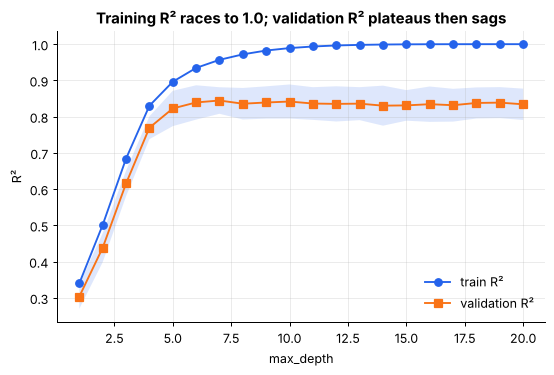

Validation R² by depth: {np.int64(1): np.float64(0.304), np.int64(3): np.float64(0.616), np.int64(5): np.float64(0.823), np.int64(7): np.float64(0.845), np.int64(10): np.float64(0.842), np.int64(15): np.float64(0.831), np.int64(20): np.float64(0.834)}


In [7]:
depths = np.arange(1, 21)
tr, va = validation_curve(DecisionTreeRegressor(random_state=0), Xtr, ytr, param_name="max_depth", param_range=depths,
                          cv=KFold(5, shuffle=True, random_state=0), scoring="r2")
plt.plot(depths, tr.mean(1), "o-", label="train R²"); plt.plot(depths, va.mean(1), "s-", label="validation R²")
plt.fill_between(depths, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.15)
plt.xlabel("max_depth"); plt.ylabel("R²"); plt.legend(); plt.title("Training R² races to 1.0; validation R² plateaus then sags"); plt.show()
print("Validation R² by depth:", dict(zip(depths[[0, 2, 4, 6, 9, 14, 19]], va.mean(1)[[0, 2, 4, 6, 9, 14, 19]].round(3))))

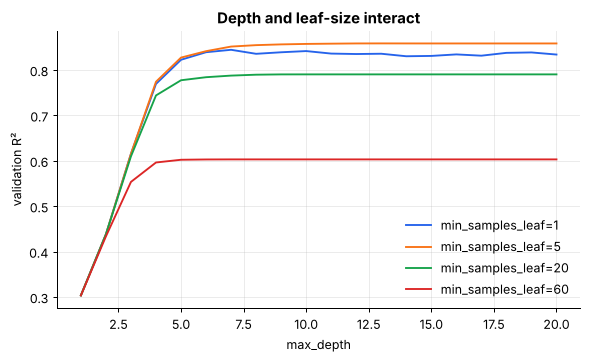

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for leaf in [1, 5, 20, 60]:
    scores = [cross_val_score(DecisionTreeRegressor(max_depth=d, min_samples_leaf=leaf, random_state=0), Xtr, ytr, cv=KFold(5, shuffle=True, random_state=0), scoring="r2").mean() for d in depths]
    ax.plot(depths, scores, label=f"min_samples_leaf={leaf}")
ax.set_xlabel("max_depth"); ax.set_ylabel("validation R²"); ax.legend(); ax.set_title("Depth and leaf-size interact"); plt.show()

> 💡 **Pro tip.**
>
> In practice, tune **`min_samples_leaf`** (or `ccp_alpha`) and let `max_depth` be generous (or unlimited). Constraining leaf size directly controls how noisy each leaf's average can be.

### Post-pruning with `ccp_alpha`
Grow a big tree, then let cost-complexity pruning snip the least valuable branches:

In [9]:
full = DecisionTreeRegressor(random_state=0).fit(Xtr, ytr)
path = full.cost_complexity_pruning_path(Xtr, ytr)
print(f"Unpruned tree: {full.get_n_leaves()} leaves, train R² = {full.score(Xtr, ytr):.3f}, test R² = {full.score(Xte, yte):.3f}")
for a in [0.05, 0.15, 0.5, 2.0]:
    p = DecisionTreeRegressor(random_state=0, ccp_alpha=a).fit(Xtr, ytr)
    print(f"ccp_alpha={a:<5}: {p.get_n_leaves():>4} leaves, train R² = {p.score(Xtr, ytr):.3f}, test R² = {p.score(Xte, yte):.3f}")

Unpruned tree: 1592 leaves, train R² = 1.000, test R² = 0.737
ccp_alpha=0.05 :  156 leaves, train R² = 0.978, test R² = 0.759
ccp_alpha=0.15 :   77 leaves, train R² = 0.956, test R² = 0.744
ccp_alpha=0.5  :   36 leaves, train R² = 0.922, test R² = 0.748
ccp_alpha=2.0  :   19 leaves, train R² = 0.864, test R² = 0.648


---
## 🏠 6. Trees on the house prices: and an honest comparison

How does a tuned tree compare with the linear model from Lesson 02? We'll also try the **log-target trick** for trees: since a leaf predicts an *average*, taking logs stops a few very expensive houses from dominating the squared error.

In [10]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(DecisionTreeRegressor(random_state=0), {"max_depth": [4, 6, 8, 10, 14, None], "min_samples_leaf": [1, 5, 10, 20, 40]},
                    cv=KFold(5, shuffle=True, random_state=0), scoring="r2").fit(Xtr, ytr)
tree_raw = grid.best_estimator_
print("best parameters (raw price):", grid.best_params_, "| CV R² =", round(grid.best_score_, 3))

grid_log = GridSearchCV(DecisionTreeRegressor(random_state=0), {"max_depth": [6, 8, 10, 14, None], "min_samples_leaf": [1, 5, 10, 20]},
                        cv=KFold(5, shuffle=True, random_state=0), scoring="r2").fit(Xtr, np.log(ytr))
tree_log = grid_log.best_estimator_
print("best parameters (log price):", grid_log.best_params_)

# linear baseline from Lesson 02 (log target)
sc = StandardScaler().fit(Xtr); lin = LinearRegression().fit(sc.transform(Xtr), np.log(ytr))
results = pd.DataFrame({
    "Tree (raw price)":  [r2_score(yte, tree_raw.predict(Xte)),  np.sqrt(mean_squared_error(yte, tree_raw.predict(Xte)))],
    "Tree (log price)":  [r2_score(yte, np.exp(tree_log.predict(Xte))), np.sqrt(mean_squared_error(yte, np.exp(tree_log.predict(Xte))))],
    "Linear (log price)": [r2_score(yte, np.exp(lin.predict(sc.transform(Xte)))), np.sqrt(mean_squared_error(yte, np.exp(lin.predict(sc.transform(Xte)))))],
}, index=["test R²", "test RMSE (M KES)"]).T
display(results.round(3))

best parameters (raw price): {'max_depth': 14, 'min_samples_leaf': 5} | CV R² = 0.859


best parameters (log price): {'max_depth': 10, 'min_samples_leaf': 5}


,test R²,test RMSE (M KES)
Tree (raw price),0.797,6.908
Tree (log price),0.880,5.308
Linear (log price),0.932,3.985


**Read this carefully: it is an important lesson.** On this dataset the (log-)linear model *beats* a single tree. Why? The data's true structure is smooth and multiplicative, which a straight-line model captures with a handful of parameters, while a tree must approximate a smooth surface with a coarse *staircase* and needs lots of data to do it well. Trees shine when there are **thresholds, interactions and non-linearities** that a line can't express. **No algorithm wins everywhere**: that's why the whole course is about *choosing*. (Trees will get a big boost in the next lesson, when we average many of them.)

---
## 📖 7. Reading the tree: interpretability

A key reason people love trees: you can *show* a manager how the model thinks.

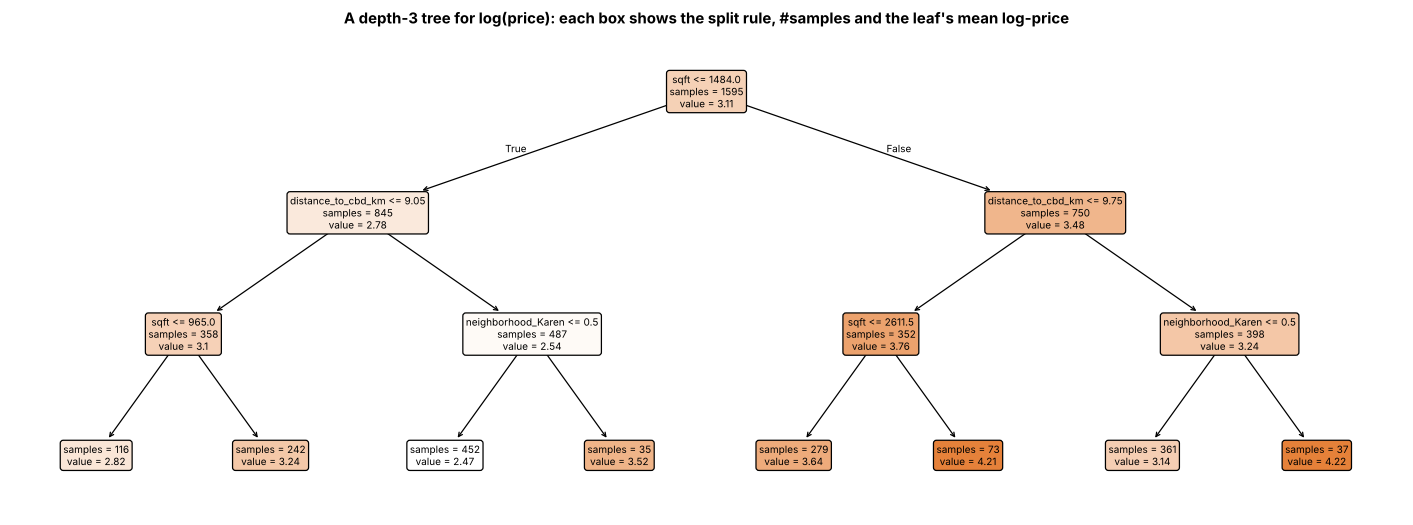

|--- sqft <= 1484.00
|   |--- distance_to_cbd_km <= 9.05
|   |   |--- sqft <= 965.00
|   |   |   |--- value: [2.82]
|   |   |--- sqft >  965.00
|   |   |   |--- value: [3.24]
|   |--- distance_to_cbd_km >  9.05
|   |   |--- neighborhood_Karen <= 0.50
|   |   |   |--- value: [2.47]
|   |   |--- neighborhood_Karen >  0.50
|   |   |   |--- value: [3.52]
|--- sqft >  1484.00
|   |--- distance_to_cbd_km <= 9.75
|   |   |--- sqft <= 2611.50
|   |   |   |--- value: [3.64]
|   |   |--- sqft >  2611.50
|   |   |   |--- value: [4.21]
|   |--- distance_to_cbd_km >  9.75
|   |   |--- neighborhood_Karen <= 0.50
|   |   |   |--- value: [3.14]
|   |   |--- neighborhood_Karen >  0.50
|   |   |   |--- value: [4.22]



In [11]:
small = DecisionTreeRegressor(max_depth=3, min_samples_leaf=30, random_state=0).fit(Xtr, np.log(ytr))
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(small, feature_names=list(Xtr.columns), filled=True, rounded=True, fontsize=8, ax=ax, precision=2, impurity=False)
plt.title("A depth-3 tree for log(price): each box shows the split rule, #samples and the leaf's mean log-price"); plt.show()
print(export_text(small, feature_names=list(Xtr.columns), max_depth=3)[:1400])

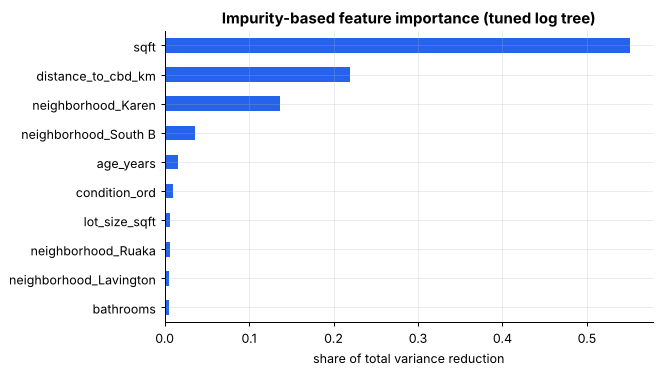

In [12]:
imp = pd.Series(tree_log.feature_importances_, index=Xtr.columns).sort_values()
imp.tail(10).plot.barh(color="#2563eb"); plt.title("Impurity-based feature importance (tuned log tree)"); plt.xlabel("share of total variance reduction"); plt.show()

> ⚠️ **Watch out.**
>
> Impurity importances are **biased towards features with many distinct values** (like `sqft` or `lot_size_sqft`) and are computed on training data. For trustworthy rankings use *permutation importance* on held-out data (Lesson 05).

**Another gift: no scaling needed.** Splits only compare a feature with a threshold, so any monotonic rescaling leaves the tree unchanged:

In [13]:
t1 = DecisionTreeRegressor(max_depth=6, random_state=0).fit(Xtr, ytr)
Xtr_big = Xtr.copy(); Xtr_big["sqft"] *= 1000; Xte_big = Xte.copy(); Xte_big["sqft"] *= 1000
t2 = DecisionTreeRegressor(max_depth=6, random_state=0).fit(Xtr_big, ytr)
print("Same predictions after multiplying sqft by 1000?", np.allclose(t1.predict(Xte), t2.predict(Xte_big)))

Same predictions after multiplying sqft by 1000? True


---
## ⚠️ 8. Weaknesses you must know

### 8a. Instability (high variance)
Change the training data slightly and the tree can change *completely*: a tiny shift at the root alters everything below it.

In [14]:
rng = np.random.default_rng(0); rows = []
for b in range(8):
    idx = rng.choice(len(Xtr), len(Xtr), replace=True)                    # a bootstrap resample
    t = DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=0).fit(Xtr.iloc[idx], ytr.iloc[idx])
    rows.append({"resample": b, "root question": f"{Xtr.columns[t.tree_.feature[0]]} <= {t.tree_.threshold[0]:.2f}",
                 "left child asks": Xtr.columns[t.tree_.feature[t.tree_.children_left[0]]] if t.tree_.feature[t.tree_.children_left[0]] >= 0 else "(leaf)",
                 "test R²": round(t.score(Xte, yte), 3)})
display(pd.DataFrame(rows))

,resample,root question,left child asks,test R²
0,0,sqft <= 2117.00,distance_to_cbd_km,0.587
1,1,sqft <= 2626.50,sqft,0.492
2,2,bedrooms <= 5.50,sqft,0.542
3,3,lot_size_sqft <= 7536.00,distance_to_cbd_km,0.518
4,4,sqft <= 1946.50,distance_to_cbd_km,0.634
5,5,sqft <= 1946.50,distance_to_cbd_km,0.543
6,6,sqft <= 1770.50,distance_to_cbd_km,0.566
7,7,sqft <= 2117.00,sqft,0.534


The structure (and the score) wobbles from resample to resample. This variance is the weakness that **Random Forests** (Lesson 05) fix by averaging hundreds of such trees.

### 8b. No extrapolation
A tree can only predict averages it has seen. Beyond the training range its prediction is a **flat line**:

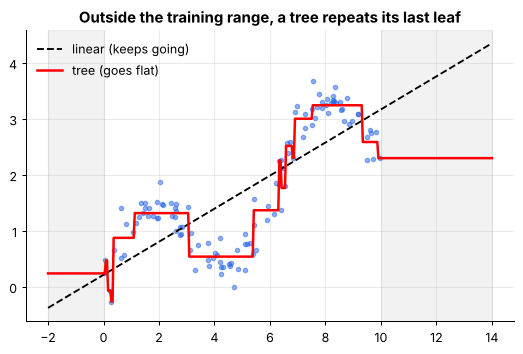

In [15]:
xe = np.linspace(-2, 14, 400).reshape(-1, 1)
lin1 = LinearRegression().fit(x1.reshape(-1, 1), y1); tr1 = DecisionTreeRegressor(max_depth=4, random_state=0).fit(x1.reshape(-1, 1), y1)
plt.scatter(x1, y1, s=12, alpha=0.5); plt.plot(xe, lin1.predict(xe), "k--", label="linear (keeps going)"); plt.plot(xe, tr1.predict(xe), "r", lw=2, label="tree (goes flat)")
plt.axvspan(-2, 0, color="gray", alpha=0.1); plt.axvspan(10, 14, color="gray", alpha=0.1); plt.legend(); plt.title("Outside the training range, a tree repeats its last leaf"); plt.show()

### 8c. Axis-aligned, staircase boundaries
A tree can only cut parallel to the axes. A diagonal relationship (e.g. $y \approx x_1+x_2$) needs many small steps to approximate, which wastes data and gives bumpy predictions.

---
## 📋 9. Cheat-sheet: the full profile of Decision Tree Regression

| Question | Answer |
|---|---|
| **Underlying concept** | Recursively split the feature space with yes/no questions; predict the average target in each final box. |
| **How it works** | Greedy CART: at each node pick the (feature, threshold) with the largest variance reduction; stop by depth/size rules; optionally prune. |
| **Mathematical foundation** | SSE / variance minimisation; leaf mean = argmin of squared error; cost-complexity pruning SSE(T)+α|T|. |
| **Important parameters** | `max_depth`, `min_samples_leaf`, `min_samples_split`, `max_leaf_nodes`, `ccp_alpha`, `max_features`, `criterion`. |
| **Advantages** | Captures non-linearity & interactions automatically; no scaling needed; mixed feature types; fast prediction; human-readable rules; robust to feature outliers. |
| **Disadvantages** | High variance (unstable); overfits if unrestricted; staircase predictions; can't extrapolate; poor with smooth/linear relations; biased importances. |
| **Complexity** | Training ≈ O(p · n log n) per tree level → O(p · n log n · depth) (balanced); prediction O(depth); memory O(#nodes). |
| **Use cases** | Rule-like domains (pricing tiers, eligibility rules), exploratory analysis, when you must *explain* the model, building block for forests and boosting. |
| **Limitations** | A single tree is rarely the most accurate model; sensitive to small data changes; struggles with additive/linear structure and with extrapolation. |

---
## 🧪 10. More worked examples

### Worked Example 1: Which split wins?

Data: $x=[2,4,6,8],\ y=[10,12,30,32]$. Compare thresholds $t=3,\ 5,\ 7$.

| t | left y | right y | SSE left | SSE right | total |
|---|---|---|---|---|---|
| 3 | [10] | [12,30,32] | 0 | $(12-24.67)^2+(30-24.67)^2+(32-24.67)^2=160.2+28.4+53.8=242.7$ | 242.7 |
| **5** | [10,12] | [30,32] | 2 | 2 | **4** |
| 7 | [10,12,30] | [32] | $(10-17.33)^2+(12-17.33)^2+(30-17.33)^2=53.8+28.4+160.2=242.7$ | 0 | 242.7 |

The best split is **t = 5**, giving leaves predicting 11 and 31.

In [16]:
xw = np.array([2, 4, 6, 8.]); yw = np.array([10, 12, 30, 32.])
for t in [3, 5, 7]:
    L, R = yw[xw <= t], yw[xw > t]; print(f"t={t}: total SSE = {sse(L) + sse(R):.1f}")

t=3: total SSE = 242.7
t=5: total SSE = 4.0
t=7: total SSE = 242.7


### Worked Example 2: Predict by walking the tree

Tree: `if sqft <= 1500: (if has_pool <= 0.5: 14 else 22) else: (if neighborhood_Karen <= 0.5: 31 else 58)`.

**Q.** A 2 400-sqft house in Karen. **A.** `sqft > 1500` → right; `neighborhood_Karen = 1 > 0.5` → right again → predict **58 million**. A 900-sqft house with a pool → `sqft ≤ 1500` → left, `has_pool = 1` → 22 million.

---
### 🧩 Problem 1: Score a split  ⭐

Write `split_sse(x, y, t)` that returns the **total SSE of the two children** when splitting at `x <= t`. Use it to compute `sse_65` and `sse_25` for the lesson's tiny data `xh, yh` at thresholds 6.5 and 2.5.

In [17]:
# ✅ SOLUTION
def split_sse(x, y, t):
    left, right = y[x <= t], y[x > t]
    s = lambda g: np.sum((g - g.mean()) ** 2) if len(g) else 0.0
    return s(left) + s(right)

sse_65 = split_sse(xh, yh, 6.5); sse_25 = split_sse(xh, yh, 2.5)
print(sse_65, sse_25)

4.0 172.75


**Why this works.** At t = 2.5 the left group is [5, 7] (SSE 2) but the right group mixes small and large prices [6, 20, 22, 21] (SSE ≈ 164), so the split barely helps.

In [18]:
check("t=6.5 gives total SSE 4", lambda: abs(sse_65 - 4.0) < 1e-9)
check("t=2.5 is much worse (> 100)", lambda: sse_25 > 100)

✅  t=6.5 gives total SSE 4
✅  t=2.5 is much worse (> 100)


---
### 🧩 Problem 2: Find the best threshold  ⭐⭐

Write `best_threshold(x, y)` that tries every midpoint between consecutive **sorted unique** x values and returns `(best_t, best_total_sse)`. Test it on the lesson data and on `xw, yw` from Worked Example 1.

In [19]:
# ✅ SOLUTION
def best_threshold(x, y):
    vals = np.unique(x); mids = (vals[:-1] + vals[1:]) / 2
    scores = [split_sse(x, y, t) for t in mids]
    k = int(np.argmin(scores))
    return mids[k], scores[k]

res1 = best_threshold(xh, yh); res2 = best_threshold(xw, yw)
print(res1, res2)

(np.float64(6.5), np.float64(4.0)) (np.float64(5.0), np.float64(4.0))


**Why this works.** This 5-line function *is* the heart of CART. A real tree runs it for every feature at every node and keeps the overall winner (our scratch class did it with cumulative sums to avoid the O(n²) loop).

In [20]:
check("tiny data: threshold 6.5", lambda: abs(res1[0] - 6.5) < 1e-9 and abs(res1[1] - 4.0) < 1e-9)
check("worked example: threshold 5", lambda: abs(res2[0] - 5.0) < 1e-9 and abs(res2[1] - 4.0) < 1e-9)

✅  tiny data: threshold 6.5
✅  worked example: threshold 5


---
### 🧩 Problem 3: Walk the tree by hand (in code)  ⭐⭐

Fit `small2 = DecisionTreeRegressor(max_depth=3, random_state=0)` on the **advertising** TV and radio columns (`tv_budget_k`, `radio_budget_k`) → `sales_k_units`.

Write `manual_predict(model, x)` that predicts one row by walking `model.tree_` yourself (arrays `children_left`, `children_right`, `feature`, `threshold`, `value`; a leaf has `children_left == -1`). Do **not** call `model.predict` inside it. Store the max absolute difference vs `model.predict` over all rows in `max_diff`.

In [21]:
# ✅ SOLUTION
ads = pd.read_csv(data_path("advertising.csv")); Xa = ads[["tv_budget_k", "radio_budget_k"]]; ya = ads["sales_k_units"]
small2 = DecisionTreeRegressor(max_depth=3, random_state=0).fit(Xa, ya)

def manual_predict(model, x):
    t = model.tree_; node = 0
    while t.children_left[node] != -1:
        node = t.children_left[node] if x[t.feature[node]] <= t.threshold[node] else t.children_right[node]
    return t.value[node][0][0]

mine_preds = np.array([manual_predict(small2, row) for row in Xa.values])
max_diff = np.abs(mine_preds - small2.predict(Xa)).max()
print(max_diff)
print(export_text(small2, feature_names=["tv", "radio"]))

0.0
|--- tv <= 157.50
|   |--- tv <= 108.45
|   |   |--- radio <= 11.35
|   |   |   |--- value: [5.73]
|   |   |--- radio >  11.35
|   |   |   |--- value: [10.60]
|   |--- tv >  108.45
|   |   |--- radio <= 21.65
|   |   |   |--- value: [11.60]
|   |   |--- radio >  21.65
|   |   |   |--- value: [15.70]
|--- tv >  157.50
|   |--- radio <= 31.15
|   |   |--- tv <= 227.40
|   |   |   |--- value: [14.95]
|   |   |--- tv >  227.40
|   |   |   |--- value: [18.54]
|   |--- radio >  31.15
|   |   |--- tv <= 204.80
|   |   |   |--- value: [19.23]
|   |   |--- tv >  204.80
|   |   |   |--- value: [22.46]



**Why this works.** Prediction is nothing more than following feature/threshold pointers until you hit a leaf; O(depth) per row, which is why trees predict so fast.

In [22]:
check("manual walk matches model.predict exactly", lambda: max_diff < 1e-9)

✅  manual walk matches model.predict exactly


---
### 🧩 Problem 4: Tune a tree on house prices  ⭐⭐

With the lesson's `Xtr, ytr, Xte, yte` (raw price target):

1. Compute the 5-fold CV R² (`KFold(5, shuffle=True, random_state=0)`) of `DecisionTreeRegressor(max_depth=d, min_samples_leaf=5, random_state=0)` for `d` in 1…12 → dict `cv_by_depth`.
2. `best_depth` = depth with the highest CV R².
3. `simple_depth` = **smallest** depth whose CV R² is within 1 % (relative) of the best.
4. `test_r2` = test R² of a tree with `simple_depth`.

In [23]:
# ✅ SOLUTION
cv_by_depth = {}
for d in range(1, 13):
    m = DecisionTreeRegressor(max_depth=d, min_samples_leaf=5, random_state=0)
    cv_by_depth[d] = cross_val_score(m, Xtr, ytr, cv=KFold(5, shuffle=True, random_state=0), scoring="r2").mean()
best_depth = max(cv_by_depth, key=cv_by_depth.get)
simple_depth = min(d for d, v in cv_by_depth.items() if v >= 0.99 * max(cv_by_depth.values()))
test_r2 = DecisionTreeRegressor(max_depth=simple_depth, min_samples_leaf=5, random_state=0).fit(Xtr, ytr).score(Xte, yte)
print(best_depth, simple_depth, round(test_r2, 3))

12 7 0.791


**Why this works.** CV R² climbs steeply until depth ~6–8 and then flattens: after that, extra depth only chases noise. The simplicity rule picks the knee of the curve.

In [24]:
check("12 depths evaluated", lambda: len(cv_by_depth) == 12)
check("best depth is deep (>= 8): the tree needs room to approximate smooth effects", lambda: best_depth >= 8)
check("simplest depth is smaller than the best", lambda: simple_depth <= best_depth)
check("test R² is decent (> 0.7)", lambda: test_r2 > 0.7)

✅  12 depths evaluated
✅  best depth is deep (>= 8): the tree needs room to approximate smooth effects
✅  simplest depth is smaller than the best
✅  test R² is decent (> 0.7)


---
### 🧩 Problem 5: Prune with cost-complexity  ⭐⭐⭐

Using `Xtr, ytr, Xte, yte`:

1. Get `alphas = full.cost_complexity_pruning_path(Xtr, ytr).ccp_alphas[:-1]` and keep **25 candidates**: `cand = np.quantile(alphas, np.linspace(0, 0.995, 25))`.
2. Choose `best_alpha` by 5-fold CV R² (`KFold(5, shuffle=True, random_state=0)`).
3. Fit the pruned tree; store `leaves_pruned` and `test_r2_pruned`, and `leaves_full` for the unpruned tree (the lesson's `full`).

In [25]:
# ✅ SOLUTION
alphas = full.cost_complexity_pruning_path(Xtr, ytr).ccp_alphas[:-1]
cand = np.quantile(alphas, np.linspace(0, 0.995, 25))
cvs = [cross_val_score(DecisionTreeRegressor(random_state=0, ccp_alpha=a), Xtr, ytr, cv=KFold(5, shuffle=True, random_state=0), scoring="r2").mean() for a in cand]
best_alpha = cand[int(np.argmax(cvs))]
pruned = DecisionTreeRegressor(random_state=0, ccp_alpha=best_alpha).fit(Xtr, ytr)
leaves_pruned = pruned.get_n_leaves(); leaves_full = full.get_n_leaves(); test_r2_pruned = pruned.score(Xte, yte)
print(leaves_full, "->", leaves_pruned, "leaves; test R² =", round(test_r2_pruned, 3), "(unpruned:", round(full.score(Xte, yte), 3), ")")

1592 -> 77 leaves; test R² = 0.744 (unpruned: 0.737 )


**Why this works.** The full tree uses ~1 600 leaves; the pruned tree about 80, with essentially the same test score. Cost-complexity pruning keeps only the branches that earn their keep: far simpler, far easier to explain.

In [26]:
check("pruning removed at least 80% of the leaves", lambda: leaves_pruned < 0.2 * leaves_full)
check("accuracy is preserved (within 0.03 of the unpruned tree)", lambda: test_r2_pruned > full.score(Xte, yte) - 0.03)

✅  pruning removed at least 80% of the leaves
✅  accuracy is preserved (within 0.03 of the unpruned tree)


---
## 🧠 Check Your Understanding
Answer each question in your head (or on paper) *before* opening the answer.

**Q1.** What does a regression tree predict in a leaf, and why that value?

<details><summary>👀 Show answer</summary>

The **mean** of the training targets in that leaf: it is the constant that minimises squared error within the group.

</details>

**Q2.** Why does an unrestricted tree get 100 % training R²? Is that a good sign?

<details><summary>👀 Show answer</summary>

It keeps splitting until each leaf holds one sample (or identical targets), memorising the data. No, it signals overfitting; look at validation error.

</details>

**Q3.** Do you need to standardise features for a decision tree? Why/why not?

<details><summary>👀 Show answer</summary>

No. Splits compare one feature with a threshold, so monotonic rescaling doesn't change which samples go left or right.

</details>

**Q4.** Your tree predicts the same value for every house larger than anything in the training data. Why?

<details><summary>👀 Show answer</summary>

Trees can't extrapolate: new points fall into the outermost leaf, whose prediction is a fixed average.

</details>

**Q5.** Two trees trained on slightly different samples look very different. Name the problem and the standard cure.

<details><summary>👀 Show answer</summary>

High variance/instability. Cure: average many trees (bagging/Random Forests (next lesson)) or constrain the tree (min_samples_leaf, pruning).

</details>

---
## 🔁 Recap

- A regression tree greedily splits to minimise children's SSE and predicts the leaf mean: a learned staircase.
- We implemented CART in ~40 lines and matched scikit-learn to floating-point precision.
- Control overfitting with `min_samples_leaf`, `max_depth`, and cost-complexity pruning (`ccp_alpha`).
- Trees need no scaling, handle interactions, and are readable, but are unstable, can't extrapolate, and can lose to linear models on smooth data.
- Single trees are weak individually; averaging many of them (Random Forest) is the fix.

### ➡️ Up next: **Random Forest Regression**
Open `05_Random_Forest_Regression.ipynb` when you're ready.

*You did the hard part: you thought about it, not just ran it. See you in the next one!* 🚀